# Accessing Data

In [2]:
# Import Libraries
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

# Load Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [3]:
# Utilise .loc to select slice columns by name
# Use .dropna to remove NaN values form salary_rate column
df.loc[:, 'salary_rate':'salary_hour_avg'].dropna(subset='salary_rate')

,salary_rate,salary_year_avg,salary_hour_avg
28,year,109500.0,NaN
43,hour,NaN,97.5
51,hour,NaN,72.5
77,year,140000.0,NaN
92,year,120000.0,NaN
...,...,...,...
785624,year,139216.0,NaN
785641,year,150000.0,NaN
785648,year,221875.0,NaN
785682,year,157500.0,NaN


# Data Cleanup

In [4]:
#Capture the median values
median_salary_year = df['salary_year_avg'].median()
median_salary_hour = df['salary_hour_avg'].median()

In [5]:
#Create new DF of df_filled and replace nan values with median
df_filled = df.copy()
df_filled['salary_year_avg'] = df_filled['salary_year_avg'].fillna(median_salary_year)
df_filled['salary_hour_avg'] = df_filled['salary_hour_avg'].fillna(median_salary_hour)
df_filled['salary_year_avg']



0         115000.0
1         115000.0
2         115000.0
3         115000.0
4         115000.0
            ...   
785736    115000.0
785737    115000.0
785738    115000.0
785739    115000.0
785740    115000.0
Name: salary_year_avg, Length: 785741, dtype: float64

In [6]:
#Drop duplicates
df_unique = df_filled.drop_duplicates()

#We've dropped this many rows
print("rows dropped =", len(df_filled) - len(df_unique))

rows dropped = 101


In [7]:
#Can specify by columns, good to remove multiple jobs posted by the same company
df_unique = df_unique.drop_duplicates(subset=['job_title', 'company_name'])
#We've dropped this many rows
print("rows dropped =", len(df_filled) - len(df_unique))

rows dropped = 277699


# Pandas

Built on top of NumPy

##  Data Management

In [8]:
#return a random sample of rows from a df (similar to head/tail)
#Can return the same answers by specifying a value to "random_state"
df_unique.sample(5, random_state=42)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
213738,Senior Data Scientist,Data Management Lead,"Taguig, Metro Manila, Philippines",via Trabajo.org,Full-time,False,Philippines,2023-07-12 22:17:54,False,False,Philippines,NaN,115000.0,45.98,Globe,NaN,NaN
356513,Senior Data Engineer,Senior Lead Data Engineer - Energetic Workplace,"São Paulo, State of São Paulo, Brazil",via GrabJobs,Full-time,False,Brazil,2023-10-22 23:39:35,True,False,Brazil,NaN,115000.0,45.98,Ewave Do Brasil Informatica Ltda,"['sas', 'sas', 'sql', 'python', 'azure', 'data...","{'analyst_tools': ['sas', 'power bi'], 'cloud'..."
581679,Data Analyst,Technical Data Analyst (Remote),Anywhere,via LinkedIn,NaN,True,Philippines,2023-07-16 09:17:56,True,False,Philippines,NaN,115000.0,45.98,MediaDev,['excel'],{'analyst_tools': ['excel']}
649012,Data Engineer,Junior SQL Data Engineer,"London, UK",via WJHL Jobs,Full-time,False,United Kingdom,2023-07-15 12:12:59,True,False,United Kingdom,NaN,115000.0,45.98,Jobleads-UK,"['sql', 't-sql', 'azure', 'ssis']","{'analyst_tools': ['ssis'], 'cloud': ['azure']..."
171348,Data Analyst,Data Analyst Marketing Intern,"Paris, France",via BeBee,Internship,False,France,2023-06-25 16:00:32,False,False,France,NaN,115000.0,45.98,Vestiaire Collective,"['sql', 'python', 'excel', 'tableau']","{'analyst_tools': ['excel', 'tableau'], 'progr..."


In [9]:
#By using the .copy() method we assign the new df a unique variable but transfer the data
df_original = dataset['train'].to_pandas()
df_altered = df_original.copy()

print(id(df_altered), id(df_original))

2030857159504 2030725938288


In [10]:
#Without the .copy method the new df inherits the original ID, meaning any changes to df_copy impact df_original
df_copy = df_original
print(id(df_copy), id(df_original))

2030725938288 2030725938288


## Pivot Tables

In [11]:
#create a pivot table by specifying the column(s) you want and the aggregation function
#size counts all rows in a column, count only counts non-NA values
df.pivot_table(index='job_title_short', aggfunc='size')

job_title_short
Business Analyst              49063
Cloud Engineer                12331
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Machine Learning Engineer     14080
Senior Data Analyst           29216
Senior Data Engineer          44563
Senior Data Scientist         36957
Software Engineer             44929
dtype: int64

In [12]:
#can create more complex pivots
df.pivot_table(values = ['salary_year_avg', 'salary_hour_avg'], index='job_title_short', aggfunc='mean')

,salary_hour_avg,salary_year_avg
job_title_short,,
Business Analyst,42.723415,91082.612833
Cloud Engineer,45.560715,111268.453846
Data Analyst,38.106918,93841.907854
Data Engineer,57.196998,130125.604250
Data Scientist,49.361403,135988.837171
Machine Learning Engineer,48.477935,126774.315972
Senior Data Analyst,47.661218,113911.363665
Senior Data Engineer,62.848496,145840.611624
Senior Data Scientist,54.105631,154206.292996


In [13]:
#Or even more complex pivots, and swap index/columns to make it longer
df.pivot_table(values = 'salary_year_avg', index='job_country' , columns='job_title_short', aggfunc='median')

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_country,,,,,,,,,,
Albania,NaN,NaN,49950.00,NaN,69981.25,NaN,NaN,NaN,157500.0,NaN
Algeria,NaN,NaN,44100.00,45000.0,NaN,NaN,NaN,NaN,NaN,NaN
Argentina,71100.0,197500.0,92771.75,96773.0,71000.00,101029.0,NaN,147500.0,NaN,174500.0
Armenia,NaN,NaN,100500.00,48750.0,NaN,87021.0,NaN,NaN,NaN,NaN
Australia,70000.0,110000.0,109500.00,106712.5,139216.00,101029.0,50640.0,147500.0,157500.0,118350.0
...,...,...,...,...,...,...,...,...,...,...
Uruguay,NaN,NaN,100500.00,NaN,NaN,50000.0,NaN,NaN,57500.0,NaN
Uzbekistan,NaN,NaN,NaN,NaN,30750.00,NaN,NaN,NaN,NaN,NaN
Vietnam,79200.0,NaN,75550.00,96773.0,70000.00,57600.0,105837.5,147500.0,79200.0,53600.0


In [14]:
#Create an array of the top 6 countries in df
top_countries = df['job_country'].value_counts().head(6).index
top_countries

Index(['United States', 'India', 'United Kingdom', 'France', 'Germany',
       'Spain'],
      dtype='str', name='job_country')

In [15]:
#Assign the pivot table
df_job_country_salary = df.pivot_table(
    values='salary_year_avg',
    index='job_country',
    columns='job_title_short',
    aggfunc='median'
)


In [16]:
#Filter pivot for only top countries
df_job_country_salary = df_job_country_salary.loc[top_countries]
df_job_country_salary

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_country,,,,,,,,,,
United States,90000.0,116100.0,90000.0,125000.0,130000.0,150000.0,110000.0,150000.0,155000.0,130000.0
India,64800.0,NaN,100500.0,147500.0,114008.0,79200.0,111175.0,147500.0,149653.0,79200.0
United Kingdom,56700.0,NaN,87750.0,110000.0,105300.0,149653.0,111175.0,147500.0,157500.0,89100.0
France,89100.0,105968.0,69175.0,98301.5,88128.0,80850.0,111175.0,147500.0,157500.0,142500.0
Germany,89100.0,89100.0,103750.0,147500.0,131560.0,89100.0,111175.0,147500.0,157500.0,84975.0
Spain,86400.0,89100.0,91977.0,133000.0,88128.0,101029.0,111175.0,147500.0,157500.0,77050.0


In [17]:
#specify desired job titles for comparison
desired_jobs = ['Data Analyst','Data Engineer', 'Data Scientist']

#filter pivot for these roles
df_job_country_salary = df_job_country_salary[desired_jobs]

df_job_country_salary

job_title_short,Data Analyst,Data Engineer,Data Scientist
job_country,,,
United States,90000.0,125000.0,130000.0
India,100500.0,147500.0,114008.0
United Kingdom,87750.0,110000.0,105300.0
France,69175.0,98301.5,88128.0
Germany,103750.0,147500.0,131560.0
Spain,91977.0,133000.0,88128.0


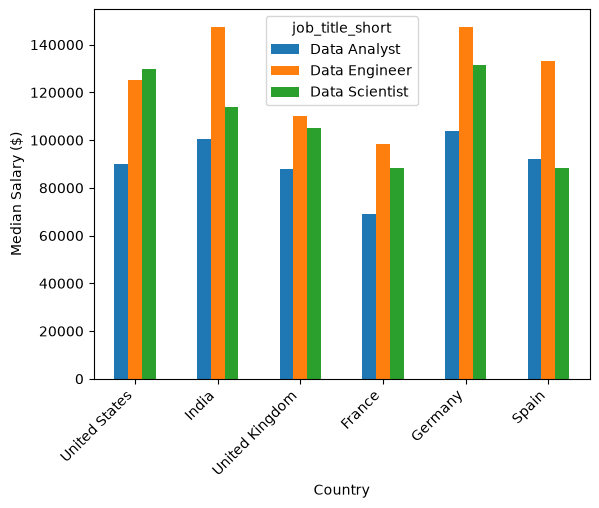

In [18]:
#plot 
df_job_country_salary.plot(kind='bar')
plt.ylabel('Median Salary ($)')
plt.xlabel('Country')
plt.xticks(rotation=45, ha='right')
plt.show()

## Index Management

In [19]:
#check in index of a dataframe (first column)
df.index

#If we check the name, it is blank
df.index.name

#You can assign one
df.index.name = 'Job_Index'

#Inspect the data type
df.index.dtype

dtype('int64')

### reset index

In [20]:
#When we subset a dataframe, the index values remain the same
df_usa = df[df['job_country']=='United States'].copy()

df_usa

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
Job_Index,,,,,,,,,,,,,,,,,
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
5,Data Engineer,GCP Data Engineer,Anywhere,via ZipRecruiter,Contractor and Temp work,True,Georgia,2023-11-07 14:01:59,False,False,United States,NaN,NaN,NaN,smart folks inc,"['python', 'sql', 'gcp']","{'cloud': ['gcp'], 'programming': ['python', '..."
6,Senior Data Engineer,Senior Data Engineer - GCP Cloud,"Dearborn, MI",via LinkedIn,Full-time,False,"Florida, United States",2023-03-27 13:18:18,False,False,United States,NaN,NaN,NaN,"Miracle Software Systems, Inc","['sql', 'python', 'java', 'sql server', 'gcp',...","{'cloud': ['gcp', 'bigquery'], 'databases': ['..."
9,Data Scientist,Data Scientist II,Anywhere,via ZipRecruiter,Full-time,True,"New York, United States",2023-04-23 13:02:57,False,False,United States,NaN,NaN,NaN,"Radwell International, LLC","['sql', 'python', 'r', 'mongodb', 'mongodb', '...","{'analyst_tools': ['excel'], 'cloud': ['azure'..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785673,Data Scientist,Asset Management Data Scientist,"New York, NY",via Trabajo.org,Full-time,False,"New York, United States",2023-10-16 06:01:53,True,False,United States,NaN,NaN,NaN,JPMorgan Chase & Co.,NaN,NaN
785685,Data Analyst,Data Analyst,"Indianapolis, IN",via Trabajo.org,Full-time,False,"Illinois, United States",2023-07-16 06:01:27,True,False,United States,NaN,NaN,NaN,"Aara Technologies, Inc","['sql', 'excel']","{'analyst_tools': ['excel'], 'programming': ['..."
785692,Data Scientist,Data Scientist- Hybrid Work Location,"Dayton, OH",via Ai-Jobs.net,Full-time,False,"Illinois, United States",2023-04-21 06:02:31,False,True,United States,year,157500.0,NaN,Tenet3,"['python', 'matlab', 'r']","{'programming': ['python', 'matlab', 'r']}"


In [21]:
#Use .reset_index() to add a new column with a new index in numerical order, the old one is still preserved
df_usa.reset_index(inplace=True)
df_usa

,Job_Index,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
2,5,Data Engineer,GCP Data Engineer,Anywhere,via ZipRecruiter,Contractor and Temp work,True,Georgia,2023-11-07 14:01:59,False,False,United States,NaN,NaN,NaN,smart folks inc,"['python', 'sql', 'gcp']","{'cloud': ['gcp'], 'programming': ['python', '..."
3,6,Senior Data Engineer,Senior Data Engineer - GCP Cloud,"Dearborn, MI",via LinkedIn,Full-time,False,"Florida, United States",2023-03-27 13:18:18,False,False,United States,NaN,NaN,NaN,"Miracle Software Systems, Inc","['sql', 'python', 'java', 'sql server', 'gcp',...","{'cloud': ['gcp', 'bigquery'], 'databases': ['..."
4,9,Data Scientist,Data Scientist II,Anywhere,via ZipRecruiter,Full-time,True,"New York, United States",2023-04-23 13:02:57,False,False,United States,NaN,NaN,NaN,"Radwell International, LLC","['sql', 'python', 'r', 'mongodb', 'mongodb', '...","{'analyst_tools': ['excel'], 'cloud': ['azure'..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
206287,785673,Data Scientist,Asset Management Data Scientist,"New York, NY",via Trabajo.org,Full-time,False,"New York, United States",2023-10-16 06:01:53,True,False,United States,NaN,NaN,NaN,JPMorgan Chase & Co.,NaN,NaN
206288,785685,Data Analyst,Data Analyst,"Indianapolis, IN",via Trabajo.org,Full-time,False,"Illinois, United States",2023-07-16 06:01:27,True,False,United States,NaN,NaN,NaN,"Aara Technologies, Inc","['sql', 'excel']","{'analyst_tools': ['excel'], 'programming': ['..."
206289,785692,Data Scientist,Data Scientist- Hybrid Work Location,"Dayton, OH",via Ai-Jobs.net,Full-time,False,"Illinois, United States",2023-04-21 06:02:31,False,True,United States,year,157500.0,NaN,Tenet3,"['python', 'matlab', 'r']","{'programming': ['python', 'matlab', 'r']}"
206290,785703,Data Analyst,Data Analyst - CRYPTOGRAPHY - Full-time,Anywhere,via Snagajob,Full-time,True,"Texas, United States",2023-01-28 06:02:55,True,False,United States,NaN,NaN,NaN,Axelon Services Corporation,NaN,NaN


### Set Index

In [22]:
#Can assign a different column to be the index
df_usa.set_index('Job_Index', inplace=True)
df_usa

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
Job_Index,,,,,,,,,,,,,,,,,
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
5,Data Engineer,GCP Data Engineer,Anywhere,via ZipRecruiter,Contractor and Temp work,True,Georgia,2023-11-07 14:01:59,False,False,United States,NaN,NaN,NaN,smart folks inc,"['python', 'sql', 'gcp']","{'cloud': ['gcp'], 'programming': ['python', '..."
6,Senior Data Engineer,Senior Data Engineer - GCP Cloud,"Dearborn, MI",via LinkedIn,Full-time,False,"Florida, United States",2023-03-27 13:18:18,False,False,United States,NaN,NaN,NaN,"Miracle Software Systems, Inc","['sql', 'python', 'java', 'sql server', 'gcp',...","{'cloud': ['gcp', 'bigquery'], 'databases': ['..."
9,Data Scientist,Data Scientist II,Anywhere,via ZipRecruiter,Full-time,True,"New York, United States",2023-04-23 13:02:57,False,False,United States,NaN,NaN,NaN,"Radwell International, LLC","['sql', 'python', 'r', 'mongodb', 'mongodb', '...","{'analyst_tools': ['excel'], 'cloud': ['azure'..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785673,Data Scientist,Asset Management Data Scientist,"New York, NY",via Trabajo.org,Full-time,False,"New York, United States",2023-10-16 06:01:53,True,False,United States,NaN,NaN,NaN,JPMorgan Chase & Co.,NaN,NaN
785685,Data Analyst,Data Analyst,"Indianapolis, IN",via Trabajo.org,Full-time,False,"Illinois, United States",2023-07-16 06:01:27,True,False,United States,NaN,NaN,NaN,"Aara Technologies, Inc","['sql', 'excel']","{'analyst_tools': ['excel'], 'programming': ['..."
785692,Data Scientist,Data Scientist- Hybrid Work Location,"Dayton, OH",via Ai-Jobs.net,Full-time,False,"Illinois, United States",2023-04-21 06:02:31,False,True,United States,year,157500.0,NaN,Tenet3,"['python', 'matlab', 'r']","{'programming': ['python', 'matlab', 'r']}"


### Sort Index

In [23]:
#useful when grouping or pivoting data, particularly when index doesn't have a column title but you still want to sort the data
median_pivot = df_usa.pivot_table(values='salary_year_avg', index='job_title_short', aggfunc=['median','min','max'])
median_pivot.sort_index()

,median,min,max
,salary_year_avg,salary_year_avg,salary_year_avg
job_title_short,,,
Business Analyst,90000.0,35000.0,387460.0
Cloud Engineer,116100.0,42000.0,221844.0
Data Analyst,90000.0,25000.0,375000.0
Data Engineer,125000.0,23496.0,525000.0
Data Scientist,130000.0,30000.0,960000.0
Machine Learning Engineer,150000.0,44408.5,315000.0
Senior Data Analyst,110000.0,35360.0,425000.0
Senior Data Engineer,150000.0,45000.0,375000.0


## Exercise: Monthly Job Demand

In [24]:
#filter data for UK
df_uk = df[df['job_country']=='United Kingdom']
df_uk

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
Job_Index,,,,,,,,,,,,,,,,,
15,Data Engineer,Data Engineer,"Aberdeen, UK",via LinkedIn,Temp work,False,United Kingdom,2023-10-19 13:37:16,False,False,United Kingdom,NaN,NaN,NaN,Orion Group,"['python', 'sql', 'power bi']","{'analyst_tools': ['power bi'], 'programming':..."
45,Senior Data Analyst,Senior Data Analyst,"Leeds, UK",via My Stateline Jobs,Full-time,False,United Kingdom,2023-05-30 13:14:08,True,False,United Kingdom,NaN,NaN,NaN,Corecom Consulting,"['sql', 'python']","{'programming': ['sql', 'python']}"
74,Data Analyst,Data Entry/Economic Data Analyst,"Worcester, UK",via BeBee,Full-time,False,United Kingdom,2023-11-01 13:11:18,False,False,United Kingdom,NaN,NaN,NaN,ttgTalentSolutions,"['sql', 'r', 'python', 'tableau', 'power bi']","{'analyst_tools': ['tableau', 'power bi'], 'pr..."
97,Data Analyst,"Systems & Data Analyst - Exploitation, Missing...",United Kingdom,via Totaljobs,Full-time and Contractor,False,United Kingdom,2023-12-04 13:14:01,True,False,United Kingdom,NaN,NaN,NaN,Solihull Metropolitan Borough Council,NaN,NaN
152,Data Scientist,Data Science Team Lead,Anywhere,via OnlyDataJobs,Full-time,True,United Kingdom,2023-12-23 13:12:16,False,False,United Kingdom,NaN,NaN,NaN,StepStone Group,"['react', 'docker']","{'libraries': ['react'], 'other': ['docker']}"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785485,Data Analyst,Data Quality Analyst,Anywhere,via LinkedIn,Full-time,True,United Kingdom,2023-10-04 06:09:44,False,False,United Kingdom,NaN,NaN,NaN,Viatris,"['sql', 'sql server', 'excel', 'powerpoint']","{'analyst_tools': ['excel', 'powerpoint'], 'da..."
785513,Data Scientist,Data Scientist,"Glasgow, UK",via Jobs Trabajo.org,Full-time,False,United Kingdom,2023-01-22 06:21:21,False,False,United Kingdom,NaN,NaN,NaN,ASA Recruitment,"['r', 'power bi']","{'analyst_tools': ['power bi'], 'programming':..."
785522,Data Engineer,Lead Data Engineer,"London, UK",via Jobs Trabajo.org,Full-time,False,United Kingdom,2023-01-19 06:16:45,True,False,United Kingdom,NaN,NaN,NaN,bionic-services-ltd,"['sql', 'python', 'sql server', 'aws', 'snowfl...","{'analyst_tools': ['ssis'], 'cloud': ['aws', '..."


In [25]:
#Add job post month
df_uk['job_posted_month'] = df_uk['job_posted_date'].dt.strftime('%B')
df_uk

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
15,Data Engineer,Data Engineer,"Aberdeen, UK",via LinkedIn,Temp work,False,United Kingdom,2023-10-19 13:37:16,False,False,United Kingdom,NaN,NaN,NaN,Orion Group,"['python', 'sql', 'power bi']","{'analyst_tools': ['power bi'], 'programming':...",October
45,Senior Data Analyst,Senior Data Analyst,"Leeds, UK",via My Stateline Jobs,Full-time,False,United Kingdom,2023-05-30 13:14:08,True,False,United Kingdom,NaN,NaN,NaN,Corecom Consulting,"['sql', 'python']","{'programming': ['sql', 'python']}",May
74,Data Analyst,Data Entry/Economic Data Analyst,"Worcester, UK",via BeBee,Full-time,False,United Kingdom,2023-11-01 13:11:18,False,False,United Kingdom,NaN,NaN,NaN,ttgTalentSolutions,"['sql', 'r', 'python', 'tableau', 'power bi']","{'analyst_tools': ['tableau', 'power bi'], 'pr...",November
97,Data Analyst,"Systems & Data Analyst - Exploitation, Missing...",United Kingdom,via Totaljobs,Full-time and Contractor,False,United Kingdom,2023-12-04 13:14:01,True,False,United Kingdom,NaN,NaN,NaN,Solihull Metropolitan Borough Council,NaN,NaN,December
152,Data Scientist,Data Science Team Lead,Anywhere,via OnlyDataJobs,Full-time,True,United Kingdom,2023-12-23 13:12:16,False,False,United Kingdom,NaN,NaN,NaN,StepStone Group,"['react', 'docker']","{'libraries': ['react'], 'other': ['docker']}",December
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785485,Data Analyst,Data Quality Analyst,Anywhere,via LinkedIn,Full-time,True,United Kingdom,2023-10-04 06:09:44,False,False,United Kingdom,NaN,NaN,NaN,Viatris,"['sql', 'sql server', 'excel', 'powerpoint']","{'analyst_tools': ['excel', 'powerpoint'], 'da...",October
785513,Data Scientist,Data Scientist,"Glasgow, UK",via Jobs Trabajo.org,Full-time,False,United Kingdom,2023-01-22 06:21:21,False,False,United Kingdom,NaN,NaN,NaN,ASA Recruitment,"['r', 'power bi']","{'analyst_tools': ['power bi'], 'programming':...",January
785522,Data Engineer,Lead Data Engineer,"London, UK",via Jobs Trabajo.org,Full-time,False,United Kingdom,2023-01-19 06:16:45,True,False,United Kingdom,NaN,NaN,NaN,bionic-services-ltd,"['sql', 'python', 'sql server', 'aws', 'snowfl...","{'analyst_tools': ['ssis'], 'cloud': ['aws', '...",January


In [26]:
#create a pivot
uk_job_posts = df_uk.pivot_table(
    index='job_posted_month',
    columns='job_title_short',
    aggfunc='size'
)

uk_job_posts

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
April,29,7,561,611,519,8,63,155,123,18
August,22,7,610,863,657,15,96,247,181,13
December,124,31,712,1034,752,78,110,213,194,97
February,23,4,1051,1009,859,10,140,301,212,10
January,46,3,1467,1253,1142,8,169,347,326,20
July,38,5,892,960,646,13,116,321,184,12
June,14,2,736,862,636,3,102,292,154,4
March,47,5,712,789,699,8,91,224,179,19
May,23,1,614,645,486,11,60,227,153,16


In [27]:
#Add a column for the numerical month
uk_job_posts.reset_index(inplace=True)
uk_job_posts['Month_no'] = pd.to_datetime(uk_job_posts['job_posted_month'], format='%B').dt.month
uk_job_posts

job_title_short,job_posted_month,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer,Month_no
0,April,29,7,561,611,519,8,63,155,123,18,4
1,August,22,7,610,863,657,15,96,247,181,13,8
2,December,124,31,712,1034,752,78,110,213,194,97,12
3,February,23,4,1051,1009,859,10,140,301,212,10,2
4,January,46,3,1467,1253,1142,8,169,347,326,20,1
5,July,38,5,892,960,646,13,116,321,184,12,7
6,June,14,2,736,862,636,3,102,292,154,4,6
7,March,47,5,712,789,699,8,91,224,179,19,3
8,May,23,1,614,645,486,11,60,227,153,16,5
9,November,155,39,840,1242,895,50,102,359,197,90,11


In [28]:
#Sort values by numerical month
uk_job_posts.sort_values('Month_no', inplace=True)
#Index it according to the written month
uk_job_posts.set_index('job_posted_month', inplace=True)
#Drop the Month_no column
uk_job_posts.drop(columns='Month_no', inplace=True)
uk_job_posts

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,46,3,1467,1253,1142,8,169,347,326,20
February,23,4,1051,1009,859,10,140,301,212,10
March,47,5,712,789,699,8,91,224,179,19
April,29,7,561,611,519,8,63,155,123,18
May,23,1,614,645,486,11,60,227,153,16
June,14,2,736,862,636,3,102,292,154,4
July,38,5,892,960,646,13,116,321,184,12
August,22,7,610,863,657,15,96,247,181,13
September,111,32,1112,1191,898,51,139,320,221,116


In [29]:
#select for the three job titles we're interested in
top_uk_jobs = df_uk['job_title_short'].value_counts().head(3)
top_uk_jobs = top_uk_jobs.index.tolist()
top_uk_jobs


['Data Engineer', 'Data Analyst', 'Data Scientist']

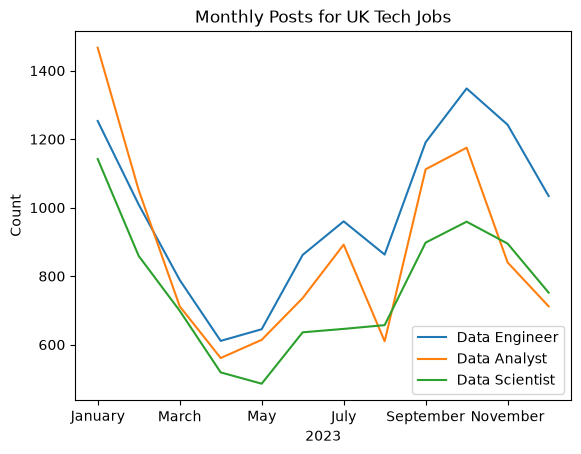

In [30]:
#Filter our dataframe for the top three jobs and plot
uk_job_posts[top_uk_jobs].plot(kind='line')
plt.title('Monthly Posts for UK Tech Jobs')
plt.xlabel('2023')
plt.ylabel('Count')
plt.legend()
plt.show()

## Merge Data Frames

In [31]:
#The two dataframes we're going to be merging
uk_job_posts
df_software_pivot = pd.read_csv("https://lukeb.co/software_csv", index_col='job_posted_month')
df_software_pivot

,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,
January,13619,9827,5108,4348
February,11456,9116,7298,4284
March,11102,8178,5814,4159
April,14037,9209,7232,4220
May,12126,8864,6718,4980
June,12003,8065,5902,4781
July,11914,8061,6839,4344
August,11571,8191,7413,4104
September,14016,8447,6139,4094


In [32]:
#merge both dfs by job_posted_month
df_merged = uk_job_posts.merge(df_software_pivot, on='job_posted_month')
df_merged

,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,,,,,,,,,,,
January,46,3,1467,1253,1142,8,169,347,326,20,13619,9827,5108,4348
February,23,4,1051,1009,859,10,140,301,212,10,11456,9116,7298,4284
March,47,5,712,789,699,8,91,224,179,19,11102,8178,5814,4159
April,29,7,561,611,519,8,63,155,123,18,14037,9209,7232,4220
May,23,1,614,645,486,11,60,227,153,16,12126,8864,6718,4980
June,14,2,736,862,636,3,102,292,154,4,12003,8065,5902,4781
July,38,5,892,960,646,13,116,321,184,12,11914,8061,6839,4344
August,22,7,610,863,657,15,96,247,181,13,11571,8191,7413,4104
September,111,32,1112,1191,898,51,139,320,221,116,14016,8447,6139,4094


In [33]:
#Find the top 5 job postings across the whole dataframe
#We can indent the actions to make them easier to follow
top_5 = (
    df_merged.sum()
    .sort_values(ascending=False)
    .head(5)
    .index
    .tolist()
    )
top_5

['Front-End Developer',
 'Back-End Developer',
 'Full-Stack Developer',
 'UI/UX Designer',
 'Data Engineer']

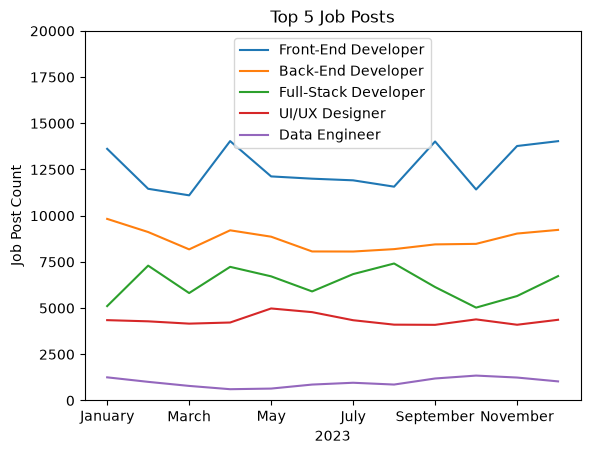

In [34]:
#Plot the data
df_merged[top_5].plot(kind='line')
plt.title('Top 5 Job Posts')
plt.xlabel('2023')
plt.ylabel('Job Post Count')
plt.ylim(0,20_000)
plt.legend()
plt.show()


## Concatenate Data Frames

In [35]:
#Append a month column to df
df['job_posted_month'] = df['job_posted_date'].dt.strftime('%b')


In [36]:
#list the months
months = df['job_posted_month'].unique()

In [37]:
#Using dictionary comprehension to assign the months to a dictionary
dict_months = {month: df[df['job_posted_month'] == month] for month in months}

In [38]:
#Can now access a dataframe for a specific month by calling the dictionary and key
dict_months['Dec']

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
7,Data Engineer,Data Engineer,Anywhere,via LinkedIn,Full-time,True,Romania,2023-12-07 13:40:49,False,False,Romania,NaN,NaN,NaN,Zitec,"['sql', 'nosql', 'gcp', 'azure', 'aws', 'bigqu...","{'cloud': ['gcp', 'azure', 'aws', 'bigquery', ...",Dec
12,Data Analyst,Stagiaire Data Analyst (H/F) - Lyon (69006),"Lyon, France",via Jobijoba,Full-time and Internship,False,France,2023-12-22 13:24:41,False,False,France,NaN,NaN,NaN,Engie,"['sql', 'php', 'excel', 'power bi', 'sap', 'ji...","{'analyst_tools': ['excel', 'power bi', 'sap']...",Dec
82,Data Engineer,Cbi Application Data Design Engineer,Singapore,via BeBee Singapore,Full-time,False,Singapore,2023-12-24 13:17:39,False,False,Singapore,NaN,NaN,NaN,Siemens,NaN,NaN,Dec
86,Data Engineer,Data Engineer,"Ridgefield Park, NJ",via SimplyHired,Full-time and Temp work,False,Sudan,2023-12-22 13:58:46,False,False,Sudan,NaN,NaN,NaN,Smartfox LLC,"['java', 'python', 'php', 'sql', 'shell', 'gcp...","{'cloud': ['gcp', 'aws'], 'libraries': ['spark...",Dec
89,Senior Data Engineer,Senior/Lead Data Engineer,"Dover, DE",via SaluteMyJob,Full-time and Part-time,False,"Illinois, United States",2023-12-04 13:08:34,False,True,United States,NaN,NaN,NaN,Capital One,"['java', 'scala', 'python', 'nosql', 'sql', 'm...","{'cloud': ['redshift', 'snowflake', 'aws', 'az...",Dec
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785609,Data Engineer,Data Engineer,"Ho Chi Minh City, Vietnam",via Trabajo.org,Full-time,False,Vietnam,2023-12-17 06:23:18,False,False,Vietnam,NaN,NaN,NaN,Fram^,"['sql', 'nosql', 'postgresql', 'mysql', 'spark...","{'databases': ['postgresql', 'mysql'], 'librar...",Dec
785623,Data Engineer,Data Engineer,"Gothenburg, Sweden",via Trabajo.org,Full-time,False,Sweden,2023-12-13 06:49:09,False,False,Sweden,NaN,NaN,NaN,Avigna AB,NaN,NaN,Dec
785640,Data Analyst,Data Analyst Lead,Thailand,via Trabajo.org,Full-time,False,Thailand,2023-12-17 06:16:04,False,False,Thailand,NaN,NaN,NaN,"Siam Piwat Co., Ltd.","['sql', 'python', 'pyspark', 'excel', 'spreads...","{'analyst_tools': ['excel', 'spreadsheet'], 'l...",Dec


<Axes: xlabel='job_posted_month'>

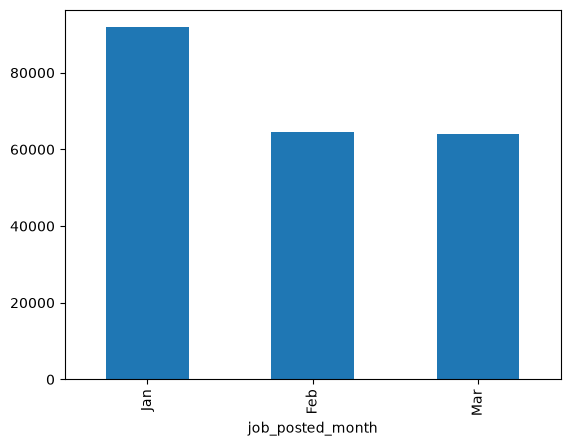

In [39]:
#Now we can concatenate these dataframes
#provide a list [] of dfs to concatenate, ignore_index removes the index column which would have duplicate values
df_Q1 = pd.concat([dict_months['Jan'], dict_months['Feb'], dict_months['Mar']], ignore_index=True)

#Check it has worked
df_Q1['job_posted_month'].value_counts().plot(kind='bar')

## Exporting Data Frames

* df.to_clipboard
* df.to_csv
* df.to_excel
* df.to_sql
* df.to_parquet
* df.to_pickle

In [42]:
#To csv
df_Q1.head(10).to_csv('Quarter_One.csv')
pd.read_csv('Quarter_One.csv', index_col=0) #Add index_col=0 to remove unnecessary column 

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
0,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr...",Jan
1,Data Scientist,Data Scientist,"Zaventem, Belgium",via BeBee Belgique,Full-time,False,Belgium,2023-01-31 13:53:38,False,False,Belgium,NaN,NaN,NaN,Devoteam,"['r', 'python', 'sql', 'pandas', 'numpy', 'sci...","{'libraries': ['pandas', 'numpy', 'scikit-lear...",Jan
2,Data Engineer,Data Engineer,"Fort Worth, TX",via LinkedIn,Full-time,False,"Texas, United States",2023-01-25 13:24:01,False,False,United States,NaN,NaN,NaN,Programmers.io,"['sql', 'python']","{'programming': ['sql', 'python']}",Jan
3,Data Engineer,Data Engineer,"San Mateo, CA",via LinkedIn,Full-time,False,"California, United States",2023-01-28 13:07:30,False,True,United States,NaN,NaN,NaN,Verkada,"['sql', 'python', 'aws', 'looker']","{'analyst_tools': ['looker'], 'cloud': ['aws']...",Jan
4,Data Scientist,Data Scientist,"São Paulo, State of São Paulo, Brazil",via BeBee,Full-time,False,Brazil,2023-01-03 23:02:27,False,False,Brazil,NaN,NaN,NaN,Mars,"['python', 'sql', 'azure']","{'cloud': ['azure'], 'programming': ['python',...",Jan
5,Senior Data Scientist,Principal Statistical Scientist,Anywhere,via LinkedIn,Full-time,True,Ireland,2023-01-31 13:54:44,False,False,Ireland,NaN,NaN,NaN,Thermo Fisher Scientific,NaN,NaN,Jan
6,Senior Data Scientist,Senior Data Scientist,"Paris, France",via Emplois Trabajo.org,Full-time,False,France,2023-01-14 13:14:25,False,False,France,NaN,NaN,NaN,Europcar Mobility Group,"['python', 'aws', 'gcp']","{'cloud': ['aws', 'gcp'], 'programming': ['pyt...",Jan
7,Business Analyst,Business Intelligence Intern,"Dallas, TX",via LinkedIn,Full-time,False,"Texas, United States",2023-01-04 13:02:07,False,False,United States,NaN,NaN,NaN,Copart,"['r', 'python', 'sql', 'tableau', 'power bi']","{'analyst_tools': ['tableau', 'power bi'], 'pr...",Jan
8,Data Engineer,Data Engineer,"Cincinnati, OH",via SimplyHired,Full-time,False,"Texas, United States",2023-01-22 13:08:53,False,False,United States,NaN,NaN,NaN,Divisions Maintenance Group,"['sql', 'nosql', 'python', 'java', 'c++', 'sca...","{'databases': ['cassandra'], 'libraries': ['ha...",Jan
9,Software Engineer,Software Engineer in Data Warehouse,"Tallinn, Estonia",via LinkedIn Estonia,Full-time,False,Estonia,2023-01-17 13:36:23,False,False,Estonia,NaN,NaN,NaN,Swedbank,['sql'],{'programming': ['sql']},Jan


In [43]:
#To Excel
df_Q1.head(10).to_excel('Quarter_One.xlsx')

In [44]:
#To sql
#from sqlalchemy import create_engine
# engine = create_engine('sqlite:///jobs.db')

# df_Q1.head(10).to_sql('Quarter_One', con=engine, if_exists='append', index=False)

In [45]:
#Both good for large datasets
#To parquet 
df_Q1.head(10).to_parquet('Quarter_One.parquet')
#To pickle
df_Q1.head(10).to_pickle('Quarter_One.pkl')

## Applying Functions

In [46]:
#Lots of nan values
df['salary_year_avg']

#Only show salary_year_avg data with values
df[pd.notna(df['salary_year_avg'])]['salary_year_avg']

#Create a filtered df
df_filtered = df[pd.notna(df['salary_year_avg'])].copy()

In [47]:
#define a function for correcting salary for inflation
def projected_salary(salary):
    return salary * 1.03

#Apply it to the salary year avg
df_filtered['salary_year_avg'].apply(projected_salary)

#Create it as a new column 
df_filtered['inflated_year_salary'] = df_filtered['salary_year_avg'].apply(projected_salary)

df_filtered.head(5)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month,inflated_year_salary
Job_Index,,,,,,,,,,,,,,,,,,,
28,Data Scientist,CRM Data Specialist,"San José Province, San José, Costa Rica",via Ai-Jobs.net,Full-time,False,Costa Rica,2023-08-01 13:37:57,False,False,Costa Rica,year,109500.0,NaN,Netskope,"['gdpr', 'excel']","{'analyst_tools': ['excel'], 'libraries': ['gd...",Aug,112785.00
77,Data Engineer,Data Engineer,"Arlington, VA",via LinkedIn,Full-time,False,Sudan,2023-06-26 14:22:54,False,False,Sudan,year,140000.0,NaN,Intelletec,"['mongodb', 'mongodb', 'python', 'r', 'sql', '...","{'analyst_tools': ['tableau'], 'cloud': ['orac...",Jun,144200.00
92,Data Engineer,Remote - Data Engineer - Permanent - W2,Anywhere,via LinkedIn,Full-time,True,"Illinois, United States",2023-02-21 13:29:59,False,True,United States,year,120000.0,NaN,Apex Systems,"['sql', 'python']","{'programming': ['sql', 'python']}",Feb,123600.00
100,Data Scientist,"Data Scientist, Risk Data Mining - USDS","Mountain View, CA",via LinkedIn,Full-time,False,"California, United States",2023-07-31 13:01:18,False,True,United States,year,228222.0,NaN,TikTok,"['sql', 'r', 'python', 'express']","{'programming': ['sql', 'r', 'python'], 'webfr...",Jul,235068.66
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,"['python', 'r', 'alteryx', 'tableau']","{'analyst_tools': ['alteryx', 'tableau'], 'pro...",Oct,91670.00


In [48]:
df_filtered[['salary_year_avg', 'inflated_year_salary']].head(5)

,salary_year_avg,inflated_year_salary
Job_Index,,
28,109500.0,112785.00
77,140000.0,144200.00
92,120000.0,123600.00
100,228222.0,235068.66
109,89000.0,91670.00


In [49]:
# We can write this quicker as a lambda function
#create a separate copy of the original data
df_anon = df[pd.notna(df['salary_year_avg'])].copy()

#Define a new column and apply the lambda function
df_anon['inflated_year_salary'] = df_anon['salary_year_avg'].apply(lambda salary: salary*1.03)

#view the result
df_anon[['salary_year_avg', 'inflated_year_salary']].head(5)

,salary_year_avg,inflated_year_salary
Job_Index,,
28,109500.0,112785.00
77,140000.0,144200.00
92,120000.0,123600.00
100,228222.0,235068.66
109,89000.0,91670.00


### Use Apply() in a real scenario

In [50]:
#Can see that job_skills is formatted as a str
df['job_skills'][1]
type(df['job_skills'][1])

df_edit = df.copy()

In [51]:
#Import ast and use literal_eval to format one cell as a list
import ast

ast.literal_eval(df_edit['job_skills'][1])

['r', 'python', 'sql', 'nosql', 'power bi', 'tableau']

In [52]:
#define a function to clean
def clean_list(skill_list):
    return ast.literal_eval(skill_list)

#Apply it
#df['job_skills'] = df['job_skills'].apply(clean_list)

#this causes an error due to the presence of nan values
df_edit[pd.isna(df_edit['job_skills'])].head(2)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN,Jun
21,Data Scientist,Stage - data scientist – génération ia de donn...,"Asnières-sur-Seine, France",via Jobijoba,Full-time,False,France,2023-02-23 13:41:21,False,False,France,NaN,NaN,NaN,Credit Agricole,NaN,NaN,Feb


In [53]:
#Redefine the function to account for this 
def clean_list(skill_list):
    if pd.notna(skill_list):
        return ast.literal_eval(skill_list)

#Apply it
df_edit['job_skills'] = df_edit['job_skills'].apply(clean_list)


In [54]:
#Now returns as type list
type(df_edit['job_skills'][2])

df_edit.head(10)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,None,NaN,Jun
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr...",Jan
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],...",Oct
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',...",Jul
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl...",Aug
5,Data Engineer,GCP Data Engineer,Anywhere,via ZipRecruiter,Contractor and Temp work,True,Georgia,2023-11-07 14:01:59,False,False,United States,NaN,NaN,NaN,smart folks inc,"[python, sql, gcp]","{'cloud': ['gcp'], 'programming': ['python', '...",Nov
6,Senior Data Engineer,Senior Data Engineer - GCP Cloud,"Dearborn, MI",via LinkedIn,Full-time,False,"Florida, United States",2023-03-27 13:18:18,False,False,United States,NaN,NaN,NaN,"Miracle Software Systems, Inc","[sql, python, java, sql server, gcp, bigquery,...","{'cloud': ['gcp', 'bigquery'], 'databases': ['...",Mar
7,Data Engineer,Data Engineer,Anywhere,via LinkedIn,Full-time,True,Romania,2023-12-07 13:40:49,False,False,Romania,NaN,NaN,NaN,Zitec,"[sql, nosql, gcp, azure, aws, bigquery, databr...","{'cloud': ['gcp', 'azure', 'aws', 'bigquery', ...",Dec
8,Business Analyst,Technology & Operations Business Analyst,"Copenhagen, Denmark",via Trabajo.org,Full-time,False,Denmark,2023-06-05 13:44:34,False,False,Denmark,NaN,NaN,NaN,Hempel,"[excel, powerpoint, power bi]","{'analyst_tools': ['excel', 'powerpoint', 'pow...",Jun


In [55]:
#refresh the edited dataframe from the original
df_edit = df.copy()

#Can also structure it as a lambda function
df_edit['job_skills'] = df_edit['job_skills'].apply(lambda skill_list: ast.literal_eval(skill_list) if pd.notna(skill_list) else skill_list)


In [56]:
df_edit.head(2)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN,Jun
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr...",Jan


## Use Apply() for rows

* Assume senior role salary inflation = 5 %
* Assume base salary inflation = 3 %

In [57]:
#refresh the edited dataframe from the original
df_filtered = df[pd.notna(df['salary_year_avg'])].copy()
df_filtered.head(2)


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
28,Data Scientist,CRM Data Specialist,"San José Province, San José, Costa Rica",via Ai-Jobs.net,Full-time,False,Costa Rica,2023-08-01 13:37:57,False,False,Costa Rica,year,109500.0,NaN,Netskope,"['gdpr', 'excel']","{'analyst_tools': ['excel'], 'libraries': ['gd...",Aug
77,Data Engineer,Data Engineer,"Arlington, VA",via LinkedIn,Full-time,False,Sudan,2023-06-26 14:22:54,False,False,Sudan,year,140000.0,NaN,Intelletec,"['mongodb', 'mongodb', 'python', 'r', 'sql', '...","{'analyst_tools': ['tableau'], 'cloud': ['orac...",Jun


In [58]:
#Create the function
def projected_salary(row):
    if "Senior" in row['job_title_short']:
        return row['salary_year_avg'] * 1.05
    else:
        return row['salary_year_avg'] * 1.03

In [59]:
#Because we are utilising information from multiple columns, we pass the whole df (df_filtered) to .apply, rather than a specific column
#We specify axis=1 because we are applying a function across rows, not down columns
df_filtered['salary_year_inflated'] = df_filtered.apply(projected_salary, axis=1)


In [60]:
#Inspect the outcome
df_filtered[['job_title_short', 'salary_year_avg','salary_year_inflated']].sample(10,random_state=42)

,job_title_short,salary_year_avg,salary_year_inflated
Job_Index,,,
429515,Data Analyst,108329.0000,111578.870000
243444,Data Scientist,89100.0000,91773.000000
759679,Senior Data Analyst,94367.0000,99085.350000
755676,Data Analyst,111175.0000,114510.250000
12796,Senior Data Scientist,126000.0000,132300.000000
721810,Data Scientist,124000.0000,127720.000000
643018,Data Analyst,90000.0000,92700.000000
260666,Data Scientist,90000.0000,92700.000000
718458,Data Scientist,132128.1875,136092.033125


## Explode

In [61]:
#Using df_edit to explode the job_skills list
df_edit.info()
df_edit.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 785741 entries, 0 to 785740
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   job_title_short        785741 non-null  str           
 1   job_title              785740 non-null  str           
 2   job_location           784696 non-null  str           
 3   job_via                785733 non-null  str           
 4   job_schedule_type      773074 non-null  str           
 5   job_work_from_home     785741 non-null  bool          
 6   search_location        785741 non-null  str           
 7   job_posted_date        785741 non-null  datetime64[us]
 8   job_no_degree_mention  785741 non-null  bool          
 9   job_health_insurance   785741 non-null  bool          
 10  job_country            785692 non-null  str           
 11  salary_rate            33067 non-null   str           
 12  salary_year_avg        22003 non-null   float64       


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN,Jun
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr...",Jan
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],...",Oct
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',...",Jul
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl...",Aug


In [62]:
#My attempt with no guidance of using .explode
#First subset job posts by the title Data Analyst, then explode the skills in these rows and only grab the top 10 
job_skills_counts = df_edit[df_edit['job_title_short'] == "Data Analyst"].explode(column='job_skills').value_counts('job_skills').head(10)


Text(0.5, 0, 'Job Posting Count')

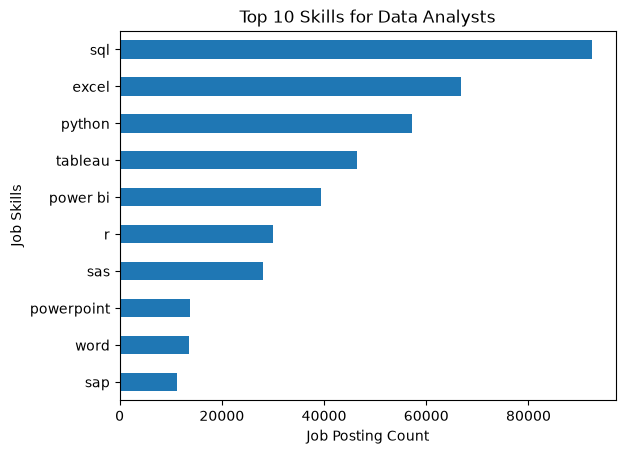

In [63]:
#Plotting the data
job_skills_counts = job_skills_counts.sort_values(ascending=True)
job_skills_counts.plot(kind='barh')
plt.title('Top 10 Skills for Data Analysts')
plt.ylabel('Job Skills')
plt.xlabel('Job Posting Count')


In [64]:
#The video groups by job title and skills
df_exploded = df_edit.explode('job_skills').copy()
df_exploded

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN,Jun
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,r,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",Jan
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,python,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",Jan
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,sql,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",Jan
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,nosql,"{'analyst_tools': ['power bi', 'tableau'], 'pr...",Jan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,kafka,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh...",Mar
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,kubernetes,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh...",Mar
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,docker,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh...",Mar


In [65]:
#Include reset_index to convert the series into a dataframe
df_skills_count = df_exploded.groupby(['job_title_short','job_skills']).size().reset_index(name='skill_count').copy()

#Sort it by the count column
df_skills_count = df_skills_count.sort_values(by='skill_count', ascending=False)

df_skills_count

,job_title_short,job_skills,skill_count
1066,Data Scientist,python,113711
865,Data Engineer,sql,113130
830,Data Engineer,python,108022
625,Data Analyst,sql,92428
1101,Data Scientist,sql,78982
...,...,...,...
462,Data Analyst,chainer,1
432,Cloud Engineer,wrike,1
410,Cloud Engineer,theano,1
24,Business Analyst,chainer,1


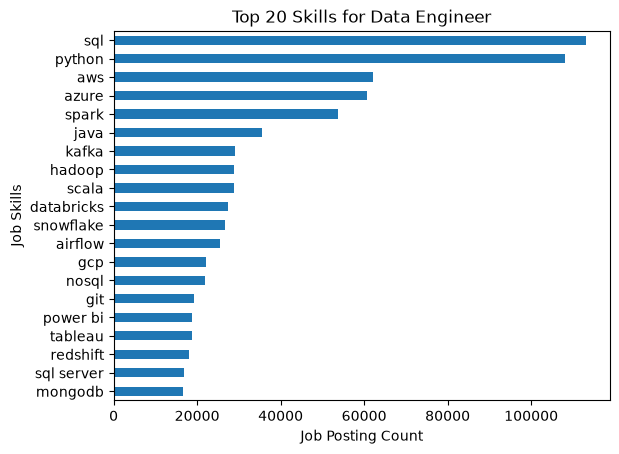

In [66]:
#Set variables for the filters
#Can set these to anything and alter the plot
title = 'Data Engineer'
top_skills = 20

#Apply the filters to get the final df
final_df = df_skills_count[df_skills_count['job_title_short'] == title].head(top_skills)

final_df
#Plotting the data
final_df.plot(kind='barh', x='job_skills', y='skill_count')
plt.gca().invert_yaxis() #Use this to invert the plotting order on yaxis
plt.title(f'Top {top_skills} Skills for {title}') #Using fstring for title to adapt it in response to variable changes
plt.ylabel('Job Skills')
plt.xlabel('Job Posting Count')
plt.legend().set_visible(False) #remove legend
plt.show()

## Exercise: Trending Skills Over Time

In [67]:
#Create a column with the numerical month
df_skilltime = df_edit.copy()
df_skilltime['job_month_no'] = df_skilltime['job_posted_date'].dt.month
df_DA = df_skilltime[df_skilltime['job_title_short'] == 'Data Analyst']
df_DA.head(2)


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month,job_month_no
Job_Index,,,,,,,,,,,,,,,,,,,
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr...",Jan,1
12,Data Analyst,Stagiaire Data Analyst (H/F) - Lyon (69006),"Lyon, France",via Jobijoba,Full-time and Internship,False,France,2023-12-22 13:24:41,False,False,France,NaN,NaN,NaN,Engie,"[sql, php, excel, power bi, sap, jira]","{'analyst_tools': ['excel', 'power bi', 'sap']...",Dec,12


In [68]:
#Explode the job skills
df_explode = df_DA.explode('job_skills')

df_pivot = (df_explode.
    pivot_table(index = 'job_month_no', #pivot by the job title month
                columns = 'job_skills',  #set the skills as the column headers
                aggfunc='size', #set counts as the values
                fill_value=0)) #replace nan values with 0

df_pivot

job_skills,airflow,airtable,alteryx,angular,angular.js,ansible,apl,arch,asana,asp.net,...,webex,windows,wire,word,workfront,wrike,wsl,xamarin,yarn,zoom
job_month_no,,,,,,,,,,,,,,,,,,,,,
1,197,17,551,63,2,20,2,1,29,34,...,17,228,6,1778,0,11,6,0,9,95
2,169,2,448,49,0,14,1,4,27,13,...,9,202,6,1235,4,2,5,0,4,41
3,181,4,442,34,0,23,6,1,17,13,...,8,194,8,1203,1,1,3,1,5,45
4,155,4,413,22,0,11,8,9,9,15,...,9,185,14,1177,8,2,1,0,6,26
5,128,8,310,30,0,19,9,2,8,21,...,11,122,3,957,3,4,0,0,7,18
6,164,14,393,29,0,14,9,4,16,16,...,8,157,14,1237,6,6,0,0,11,34
7,207,4,366,15,0,8,5,8,19,12,...,5,161,11,1069,0,3,0,0,6,38
8,197,3,413,21,0,12,10,3,13,12,...,9,184,11,1298,0,1,0,0,11,41
9,118,4,317,21,0,14,3,10,12,10,...,4,150,8,945,0,1,0,0,5,25


In [69]:
#Create a totals row
df_pivot.loc['Total'] = df_pivot.sum()
df_pivot

job_skills,airflow,airtable,alteryx,angular,angular.js,ansible,apl,arch,asana,asp.net,...,webex,windows,wire,word,workfront,wrike,wsl,xamarin,yarn,zoom
job_month_no,,,,,,,,,,,,,,,,,,,,,
1,197,17,551,63,2,20,2,1,29,34,...,17,228,6,1778,0,11,6,0,9,95
2,169,2,448,49,0,14,1,4,27,13,...,9,202,6,1235,4,2,5,0,4,41
3,181,4,442,34,0,23,6,1,17,13,...,8,194,8,1203,1,1,3,1,5,45
4,155,4,413,22,0,11,8,9,9,15,...,9,185,14,1177,8,2,1,0,6,26
5,128,8,310,30,0,19,9,2,8,21,...,11,122,3,957,3,4,0,0,7,18
6,164,14,393,29,0,14,9,4,16,16,...,8,157,14,1237,6,6,0,0,11,34
7,207,4,366,15,0,8,5,8,19,12,...,5,161,11,1069,0,3,0,0,6,38
8,197,3,413,21,0,12,10,3,13,12,...,9,184,11,1298,0,1,0,0,11,41
9,118,4,317,21,0,14,3,10,12,10,...,4,150,8,945,0,1,0,0,5,25


In [70]:
#Sort the total values by size
df_pivot.loc['Total'].sort_values(ascending=False)

#Find the column headers for these values
df_pivot.loc['Total'].sort_values(ascending=False).index

Index(['sql', 'excel', 'python', 'tableau', 'power bi', 'r', 'sas',
       'powerpoint', 'word', 'sap',
       ...
       'xamarin', 'mattermost', 'gtx', 'esquisse', 'chainer', 'capacitor',
       'nuxt.js', 'msaccess', 'ovh', 'suse'],
      dtype='str', name='job_skills', length=235)

In [71]:
#Use this to order the columns by the totals row
df_pivot = df_pivot[df_pivot.loc['Total'].sort_values(ascending=False).index]


In [72]:
#Drop the total row
df_pivot = df_pivot.drop('Total')
df_pivot

job_skills,sql,excel,python,tableau,power bi,r,sas,powerpoint,word,sap,...,xamarin,mattermost,gtx,esquisse,chainer,capacitor,nuxt.js,msaccess,ovh,suse
job_month_no,,,,,,,,,,,,,,,,,,,,,
1,11336,8170,6606,5596,4285,3607,3830,1880,1778,1251,...,0,0,0,0,0,1,1,0,0,0
2,7947,5772,4751,3936,3307,2576,2634,1291,1235,954,...,0,0,0,0,0,0,0,0,0,0
3,7868,5675,4741,4051,3176,2650,2554,1266,1203,892,...,1,0,0,0,0,0,0,0,0,1
4,7553,5496,4557,3776,3106,2399,2598,1190,1177,947,...,0,0,0,0,0,0,0,0,1,0
5,6617,4773,4070,3245,2695,2093,1940,979,957,851,...,0,0,0,0,0,0,0,1,0,0
6,7584,5724,4707,3812,3275,2442,2174,1173,1237,987,...,0,0,0,0,0,0,0,0,0,0
7,7687,5513,4831,3928,3350,2444,2118,1096,1069,996,...,0,0,1,0,0,0,0,0,0,0
8,8823,6482,5576,4533,3859,2975,2560,1332,1298,1117,...,0,0,0,0,0,0,0,0,0,0
9,6829,4886,4229,3446,3118,2146,1880,944,945,852,...,0,1,0,0,0,0,0,0,0,0


Text(0, 0.5, 'Count')

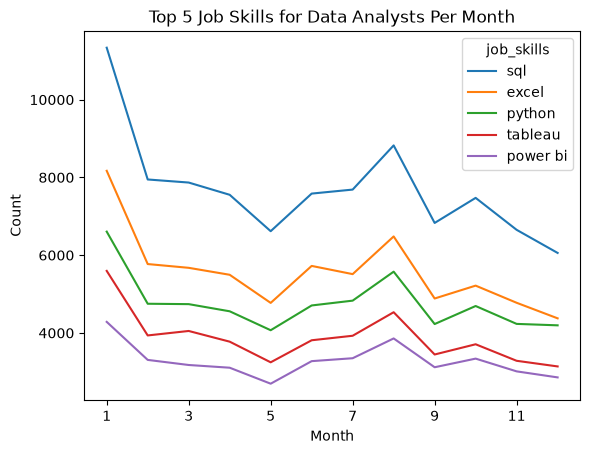

In [73]:
df_pivot.iloc[:,0:5].plot(kind='line')
plt.title('Top 5 Job Skills for Data Analysts Per Month')
plt.xlabel('Month')
plt.ylabel('Count')

# Matplotlib

In [74]:
#Using this df because the data is already formatted correctly
df_edit.info()


<class 'pandas.DataFrame'>
RangeIndex: 785741 entries, 0 to 785740
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   job_title_short        785741 non-null  str           
 1   job_title              785740 non-null  str           
 2   job_location           784696 non-null  str           
 3   job_via                785733 non-null  str           
 4   job_schedule_type      773074 non-null  str           
 5   job_work_from_home     785741 non-null  bool          
 6   search_location        785741 non-null  str           
 7   job_posted_date        785741 non-null  datetime64[us]
 8   job_no_degree_mention  785741 non-null  bool          
 9   job_health_insurance   785741 non-null  bool          
 10  job_country            785692 non-null  str           
 11  salary_rate            33067 non-null   str           
 12  salary_year_avg        22003 non-null   float64       


<Axes: xlabel='job_title_short'>

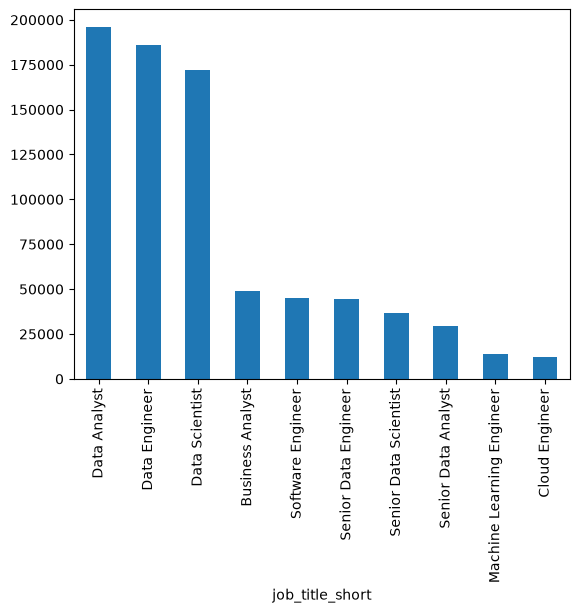

In [75]:
#This is the layout for creating subplots using mpl
fig, ax = plt.subplots(1,1)

#passing the data we want into the plot
df['job_title_short'].value_counts().plot(kind='bar', ax = ax)

## Pandas notation for laying out plots

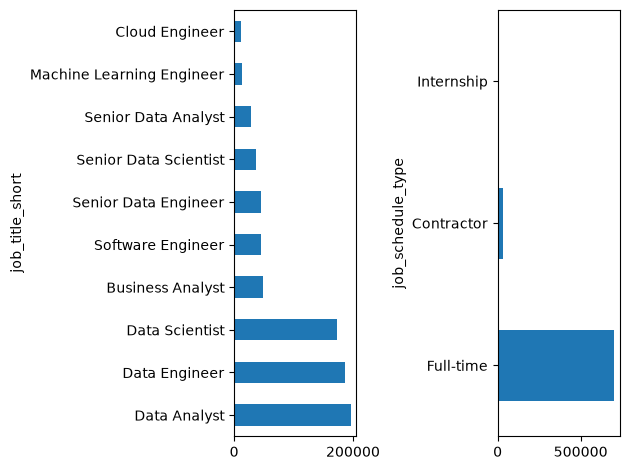

In [76]:
fig, ax = plt.subplots(1,2)
#When plotting multiple plots, you need to specify the index of variable ax
df['job_title_short'].value_counts().plot(kind='barh', ax = ax[0])
df['job_schedule_type'].value_counts().head(3).plot(kind='barh', ax = ax[1])

#passing things to variable fig applies it to the whole figure
fig.tight_layout() #tight layout stops overlap of plot items

## Matplotlib Notation for the same plots

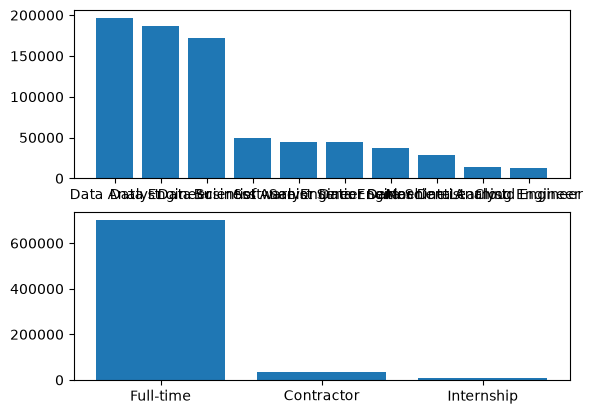

In [77]:
#More verbose method, easier to use Pandas notation
fig, ax = plt.subplots(2,1)

ax[0].bar(df_edit['job_title_short'].value_counts().index, df_edit['job_title_short'].value_counts())
ax[1].bar(df_edit['job_schedule_type'].value_counts().head(3).index, df_edit['job_schedule_type'].value_counts().head(3))

plt.tight_layout
plt.show()

## Example: Counts of top skills in job postings

In [78]:
#Include reset_index to convert the series into a dataframe
df_skills_count = df_exploded.groupby(['job_title_short','job_skills']).size().reset_index(name='skill_count').copy()

#Sort it by the count column
df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)

df_skills_count

,job_title_short,job_skills,skill_count
1066,Data Scientist,python,113711
865,Data Engineer,sql,113130
830,Data Engineer,python,108022
625,Data Analyst,sql,92428
1101,Data Scientist,sql,78982
...,...,...,...
462,Data Analyst,chainer,1
432,Cloud Engineer,wrike,1
410,Cloud Engineer,theano,1
24,Business Analyst,chainer,1


In [79]:
#specify the jobs we want to plot
titles = ['Data Scientist', 'Data Analyst' , 'Data Engineer']



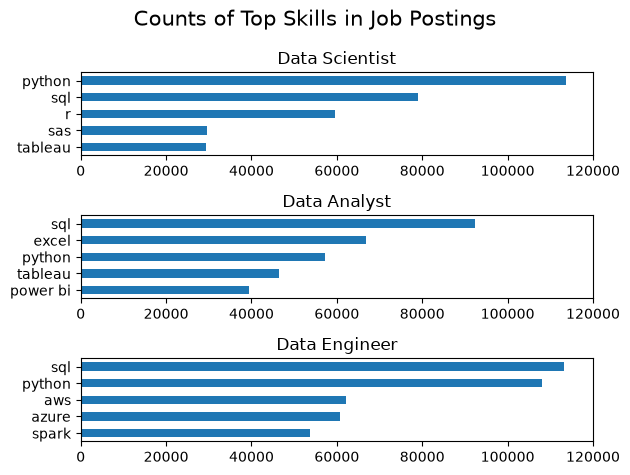

In [80]:
#Call the plot and specify the layout
fig, ax = plt.subplots(3,1)

#Within a for loop, use i to count through the list of tiles
for i, title in enumerate(titles):
    df_plot = df_skills_count[df_skills_count['job_title_short'] == title].head(5) #define the data which goes into the plot
    df_plot.plot(kind='barh', x='job_skills', y='skill_count', ax=ax[i], title=title) #specify the plot features and assign the index ax[i] so it counts through titles

#Specify preferences for all plots 
    ax[i].invert_yaxis() #invert plotting of yaxis so largest is on top
    ax[i].set_ylabel('') #remove yaxis label
    ax[i].legend().set_visible(False) #remove legend
    ax[i].set_xlim(0,120_000) #unify the xaxis
    
#Set the title for the whole figure
    fig.suptitle('Counts of Top Skills in Job Postings', fontsize=15)

#Call tight layout last to prevent overlaps
    fig.tight_layout()
    plt.show

## Pie Plots

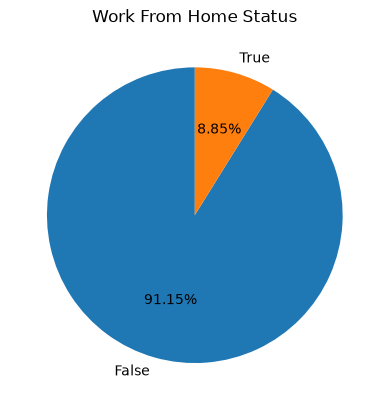

In [81]:
#Good for showing few values
df_edit['job_work_from_home'].value_counts().plot(kind = 'pie', 
                                                    startangle = 90, #can add this so values start from the top
                                                    autopct = '%1.2f%%') #% symbolises we're formatting the percentage, 1 is the minimum width, .2 for the number of decimals, f for floating point number, %% to show percentage symbol
plt.title('Work From Home Status')
plt.ylabel('')
plt.show()

In [82]:
df_edit[['job_work_from_home', 'job_no_degree_mention','job_health_insurance']]

,job_work_from_home,job_no_degree_mention,job_health_insurance
Job_Index,,,
0,False,False,False
1,False,False,False
2,False,False,False
3,False,True,False
4,False,False,False
...,...,...,...
785736,False,False,False
785737,False,False,False
785738,False,False,False


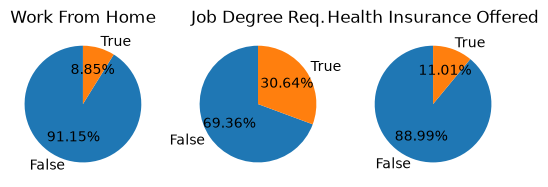

In [83]:
#call the plot
fig, ax = plt.subplots(1,3)

#define a dictionary of the column names and the title we want to give it
dict_col = {
    'job_work_from_home': 'Work From Home',
    'job_no_degree_mention': 'Job Degree Req.',
    'job_health_insurance': 'Health Insurance Offered'
}

#Using a for loop to cycle through multiple plots
#because we're calling from a dictionary, we have to pass variables (col,title) as a tuple
#enumerate lets us cycle through the items of dict_col using i
for i, (col, title) in enumerate(dict_col.items()):
    ax[i].pie(df_edit[col].value_counts(), startangle=90, autopct='%1.2f%%', labels = ['False','True'])
    ax[i].set_title(title)
    
plt.show()


## Scatter Plots

In [84]:
#subset by data analyst
df_da = df_edit[df_edit['job_title_short'] == 'Data Analyst'].copy()

#explode the skills
df_explode = df_da.explode('job_skills')



In [85]:
#group by and apply functions to the df
skill_stats = df_explode.groupby('job_skills').agg( #multiple functions are being applied so we use agg
    skill_count = ('job_skills', 'count'), #skill count is the count of job skills column
    median_salary = ('salary_year_avg', 'median')
)

top_skill_stats = skill_stats.sort_values('skill_count', ascending=False).head(10)

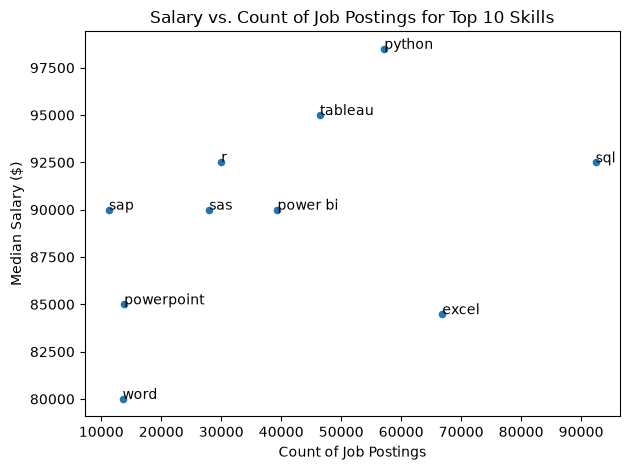

In [86]:
#plot the data
top_skill_stats.plot(kind='scatter', x='skill_count', y='median_salary')

#make it look nice
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Salary ($)')
plt.title('Salary vs. Count of Job Postings for Top 10 Skills')
plt.tight_layout()    

#to add labels to the data, we need to loop through the index of the df 
for i, txt in enumerate(top_skill_stats.index):
    plt.text(top_skill_stats['skill_count'].iloc[i], top_skill_stats['median_salary'].iloc[i], txt) #use iloc to return the numerical values associated with i

plt.show()

# Advanced Customisation

## Line Plot

Text(0, 0.5, 'Count')

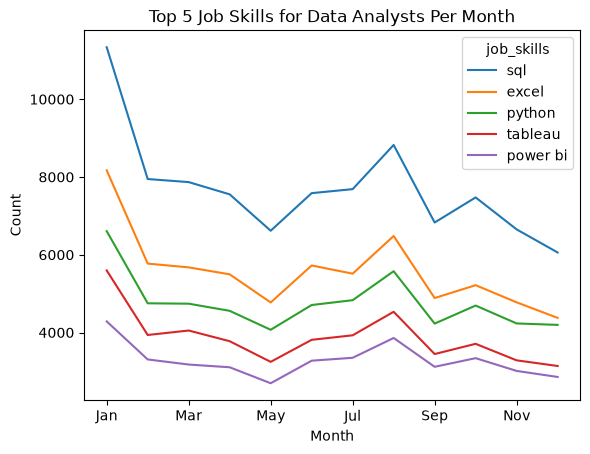

In [87]:
#Explode the job skills
df_explode = df_DA.explode('job_skills')

df_pivot = (df_explode.
    pivot_table(index = 'job_month_no', #pivot by the job title month
                columns = 'job_skills',  #set the skills as the column headers
                aggfunc='size', #set counts as the values
                fill_value=0)) #replace nan values with 0

# Sort skills by count
df_pivot.loc['Total'] = df_pivot.sum()
df_pivot = df_pivot[df_pivot.loc['Total'].sort_values(ascending=False).index]
df_pivot = df_pivot.drop('Total')

#Sort months by number
df_pivot = df_pivot.reset_index()
df_pivot['job_posted_month'] = df_pivot['job_month_no'].apply(lambda x: pd.to_datetime(x, format = '%m').strftime('%b'))
df_pivot = df_pivot.set_index('job_posted_month')
df_pivot = df_pivot.drop(columns='job_month_no')

#A previous plot we did
df_pivot.iloc[:,0:5].plot(kind='line')
plt.title('Top 5 Job Skills for Data Analysts Per Month')
plt.xlabel('Month')
plt.ylabel('Count')

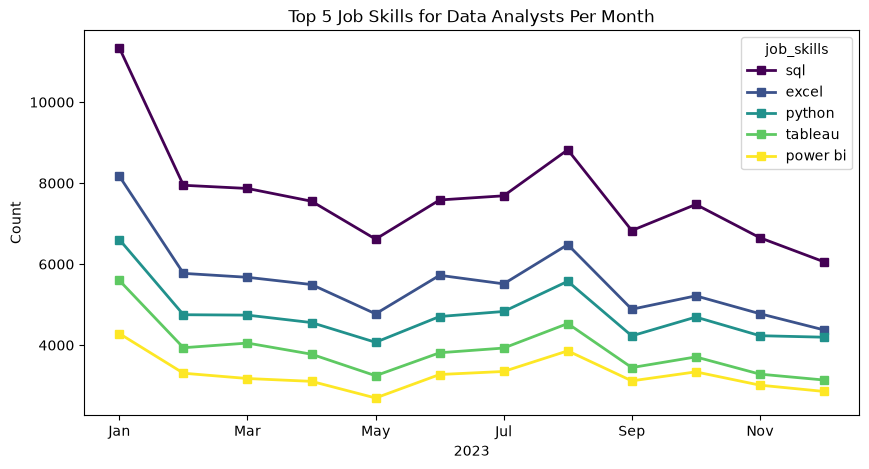

In [88]:
#Upgrading the plot formatting
df_pivot.iloc[:,0:5].plot(
    kind='line', 
    linewidth=2,
    linestyle='-', #options: '-', '--', '-.', ':'
    colormap='viridis', #options: 'viridis', 'plasma', 'magma', 'inferno', 'cividis'
    markersize=6, 
    marker='s', #options: 'o', 'x', '+', '*', 's', ',', '.', '1', '2', '3', '4'
    figsize=(10,5)    
    )

plt.xlabel('2023')
plt.ylabel('Count')
plt.title('Top 5 Job Skills for Data Analysts Per Month')

plt.show()

## Scatter Plot

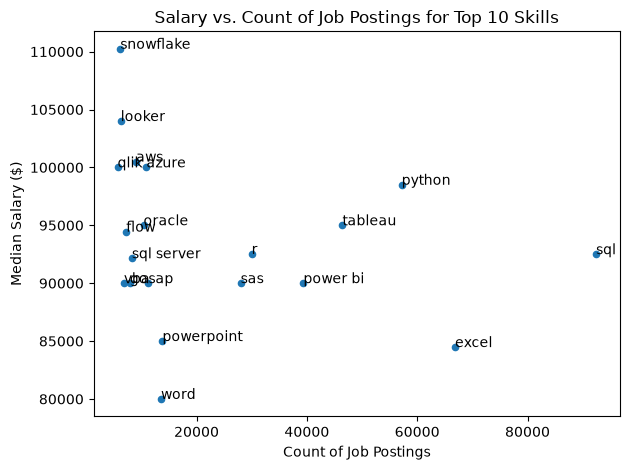

In [89]:
#Original Plot
skill_no = 20
top_skill_stats = skill_stats.sort_values('skill_count', ascending=False).head(skill_no)

#plot the data
top_skill_stats.plot(kind='scatter', x='skill_count', y='median_salary')

#make it look nice
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Salary ($)')
plt.title('Salary vs. Count of Job Postings for Top 10 Skills')
plt.tight_layout()    

#to add labels to the data, we need to loop through the index of the df 
for i, txt in enumerate(top_skill_stats.index):
    plt.text(top_skill_stats['skill_count'].iloc[i], top_skill_stats['median_salary'].iloc[i], txt) #use iloc to return the numerical values associated with i

plt.show()

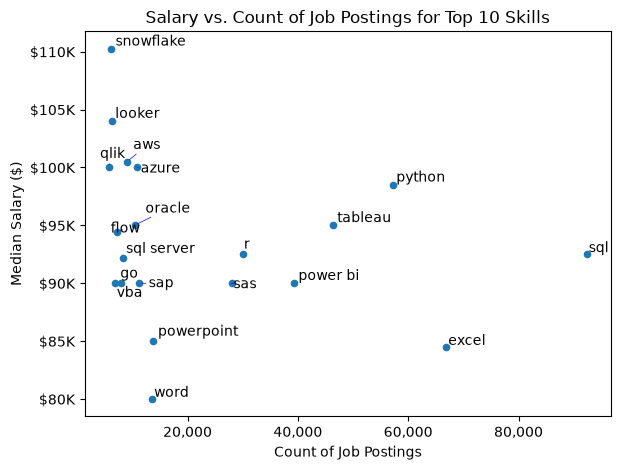

In [90]:
from adjustText import adjust_text

#plot the data
top_skill_stats.plot(kind='scatter', x='skill_count', y='median_salary')

#create an empty list
texts = []
#to add labels to the data, we need to loop through the index of the df 
for i, txt in enumerate(top_skill_stats.index):
    texts.append(plt.text(top_skill_stats['skill_count'].iloc[i], top_skill_stats['median_salary'].iloc[i], txt)) #append the empty list with the text coordinate data
    
adjust_text(texts,  #pass the list of text info from texts
            arrowprops=dict(arrowstyle='-',  #set the arrow style
                            color = 'b',  #set arrow colour
                            lw=0.5)) #set line width


ax = plt.gca() #assign gca function to ax

#make it look nice
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Salary ($)')
plt.title('Salary vs. Count of Job Postings for Top 10 Skills')
plt.tight_layout()  

ax.yaxis.set_major_formatter( #call ax that we assigned above
    plt.FuncFormatter( #this allows us to call func formatter 
        lambda y, pos: f'${int(y/1000)}K' #format the yaxis labels as an f string inside of a lambda function, have to pass the pos argument even if unused
        )
    )

#Do the same to make the x axis labels comma separated
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{int(x):,}'))

plt.show()

# Statistical Plots

## Histograms

In [91]:
#subset the data for US data analysts
us_da = df_edit[(df_edit['job_title_short'] == 'Data Analyst') &(df_edit['job_country'] == 'United States')].copy()
us_da.head(3)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
36,Data Analyst,Data Analyst,"Des Moines, IA",via Trabajo.org,Full-time,False,"Illinois, United States",2023-11-06 13:01:22,False,True,United States,NaN,NaN,NaN,Assuredpartners,NaN,NaN,Nov
68,Data Analyst,Sr. Research Data Analyst,"Baltimore, MD",via ZipRecruiter,Full-time,False,"New York, United States",2023-03-24 13:01:00,False,False,United States,NaN,NaN,NaN,Johns Hopkins Medicine,"[r, zoom]","{'programming': ['r'], 'sync': ['zoom']}",Mar
73,Data Analyst,Entry level / Systems Data Analyst (Remote),Anywhere,via LinkedIn,Contractor,True,"Illinois, United States",2023-06-16 13:18:22,True,True,United States,NaN,NaN,NaN,Soft Magic,"[word, excel, powerpoint, outlook]","{'analyst_tools': ['word', 'excel', 'powerpoin...",Jun


<Axes: ylabel='Frequency'>

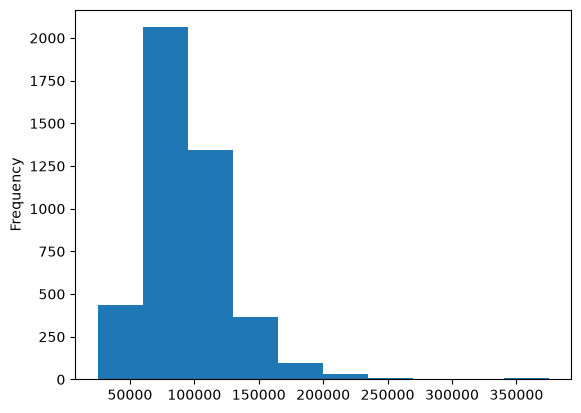

In [92]:
#Simple histogram
us_da['salary_year_avg'].plot(kind='hist')

Text(0.5, 1.0, 'Distribution of United States Annual Data Analyst Salaries')

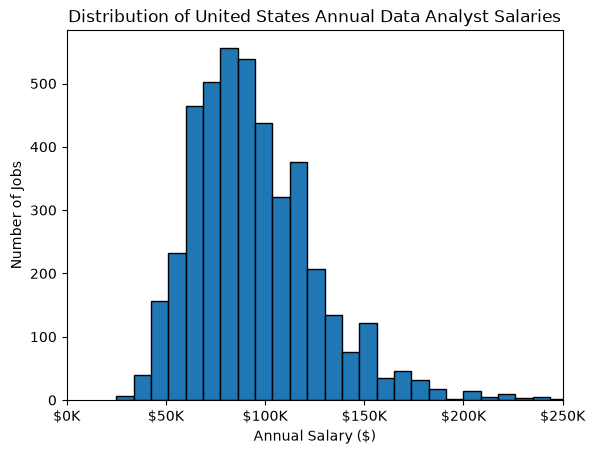

In [93]:
#Customised Histogram
us_da['salary_year_avg'].plot(kind='hist', bins=40, edgecolor = 'black')

plt.xlim(0,250_000)

ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

plt.xlabel('Annual Salary ($)')
plt.ylabel('Number of Jobs')
plt.title('Distribution of United States Annual Data Analyst Salaries')

## Box Plots

In [94]:
df_usa2 = df_usa.dropna(subset=['salary_year_avg']).copy()
df_usa2.head(3)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
Job_Index,,,,,,,,,,,,,,,,,
92,Data Engineer,Remote - Data Engineer - Permanent - W2,Anywhere,via LinkedIn,Full-time,True,"Illinois, United States",2023-02-21 13:29:59,False,True,United States,year,120000.0,NaN,Apex Systems,"['sql', 'python']","{'programming': ['sql', 'python']}"
100,Data Scientist,"Data Scientist, Risk Data Mining - USDS","Mountain View, CA",via LinkedIn,Full-time,False,"California, United States",2023-07-31 13:01:18,False,True,United States,year,228222.0,NaN,TikTok,"['sql', 'r', 'python', 'express']","{'programming': ['sql', 'r', 'python'], 'webfr..."
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,"['python', 'r', 'alteryx', 'tableau']","{'analyst_tools': ['alteryx', 'tableau'], 'pro..."


<Axes: >

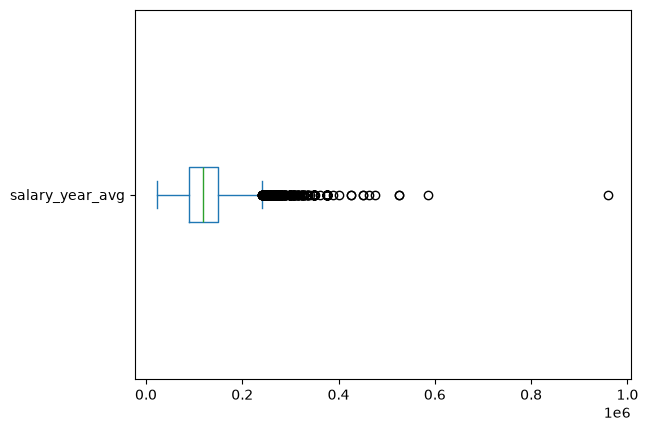

In [95]:
#Matplotlib
#plt.boxplot(df_usa2['salary_year_avg'])

#Pandas
df_usa2['salary_year_avg'].plot(kind='box', vert=False)


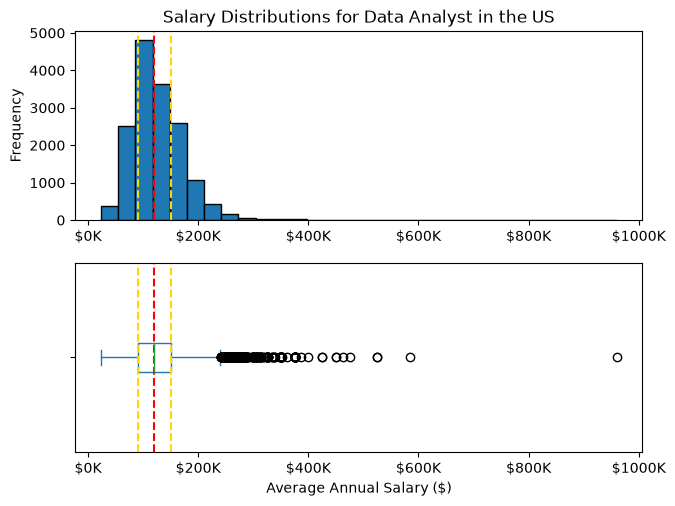

In [96]:
#Create the multiplot
fig, ax = plt.subplots(2,1)
fig.tight_layout(h_pad=1)

#Histogram
df_usa2['salary_year_avg'].plot(kind='hist',ax=ax[0],bins=30, edgecolor='black')
ax[0].set_title('Salary Distributions for Data Analyst in the US')
ax[0].set_xlabel('')
ax[0].set_ylabel('Frequency')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

#Histogram Lines
ax[0].axvline(df_usa2['salary_year_avg'].median(), color='red', linestyle='--')
ax[0].axvline(df_usa2['salary_year_avg'].quantile(0.25), color='gold', linestyle='--')
ax[0].axvline(df_usa2['salary_year_avg'].quantile(0.75), color='gold', linestyle='--')

#Boxplot
df_usa2['salary_year_avg'].plot(kind='box', ax=ax[1], vert=False)
ax[1].set_yticklabels('')
ax[1].set_xlabel('Average Annual Salary ($)')
ax[1].set_ylabel('')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

#Boxplot Lines
ax[1].axvline(df_usa2['salary_year_avg'].median(), color='red', linestyle='--')
ax[1].axvline(df_usa2['salary_year_avg'].quantile(0.25), color='gold', linestyle='--')
ax[1].axvline(df_usa2['salary_year_avg'].quantile(0.75), color='gold', linestyle='--')

plt.show()

In [97]:
job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']


df_usa3 = df_edit[
    (df_edit['job_title_short'].isin(job_titles)) &
    (df_edit['job_country'] == 'United States')
    ].copy()

df_usa3 = df_usa3.dropna(subset='salary_year_avg')

df_usa3.head(3)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
92,Data Engineer,Remote - Data Engineer - Permanent - W2,Anywhere,via LinkedIn,Full-time,True,"Illinois, United States",2023-02-21 13:29:59,False,True,United States,year,120000.0,NaN,Apex Systems,"[sql, python]","{'programming': ['sql', 'python']}",Feb
100,Data Scientist,"Data Scientist, Risk Data Mining - USDS","Mountain View, CA",via LinkedIn,Full-time,False,"California, United States",2023-07-31 13:01:18,False,True,United States,year,228222.0,NaN,TikTok,"[sql, r, python, express]","{'programming': ['sql', 'r', 'python'], 'webfr...",Jul
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,"[python, r, alteryx, tableau]","{'analyst_tools': ['alteryx', 'tableau'], 'pro...",Oct


In [98]:
#list comprehension to index the salary year avg values for each job in job_titles
job_list = [df_usa3[df_usa3['job_title_short'] == job_title]['salary_year_avg'] for job_title in job_titles]
job_list[0]

Job_Index
109        89000.0
180        90250.0
410       133285.0
988        62623.0
1413       71300.0
            ...   
782637     70000.0
782798    111175.0
783588    125000.0
783866    115000.0
784882     87500.0
Name: salary_year_avg, Length: 4350, dtype: float64

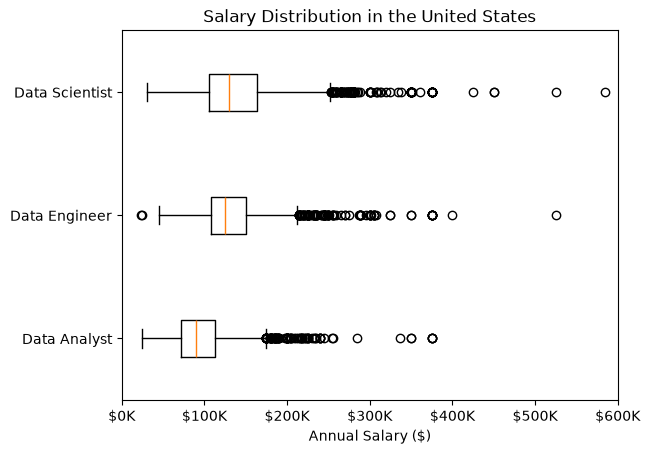

In [99]:
plt.boxplot(job_list, tick_labels=job_titles, orientation='horizontal')

plt.title('Salary Distribution in the United States')
plt.xlabel('Annual Salary ($)')
plt.ylabel('')

ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000):,}K')) #format the xaxis

plt.xlim(0,600_000) #filter out some outliers and focus more on the majority of data

plt.show()

# Exercise: Skill Pay Analysis

In [100]:
#subset data
df_usa4 = df_edit[(df_edit['job_title_short'] == 'Data Analyst') & (df_edit['job_country'] == 'United States')].dropna(subset='salary_year_avg').copy()
df_usa4.head(3)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,"[python, r, alteryx, tableau]","{'analyst_tools': ['alteryx', 'tableau'], 'pro...",Oct
180,Data Analyst,Data Analyst III,"Dos Palos, CA",via My ArkLaMiss Jobs,Full-time,False,"California, United States",2023-02-27 13:00:39,False,True,United States,year,90250.0,NaN,California Health & Wellness,"[excel, powerpoint]","{'analyst_tools': ['excel', 'powerpoint']}",Feb
410,Data Analyst,IT Business Lead Data Analyst - VP - Hybrid,"Atlantic Beach, FL",via ComputerJobs.com,Full-time,False,Georgia,2023-01-10 13:59:02,False,False,United States,year,133285.0,NaN,Citi,"[sql, word, excel, visio, powerpoint, sharepoint]","{'analyst_tools': ['word', 'excel', 'visio', '...",Jan


In [101]:
#Explode job
df4_explode = df_usa4.explode('job_skills')
df4_explode.head(3)


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills,job_posted_month
Job_Index,,,,,,,,,,,,,,,,,,
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,python,"{'analyst_tools': ['alteryx', 'tableau'], 'pro...",Oct
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,r,"{'analyst_tools': ['alteryx', 'tableau'], 'pro...",Oct
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,alteryx,"{'analyst_tools': ['alteryx', 'tableau'], 'pro...",Oct


In [102]:
#aggregate counts of job skills and their associated median salary
df4_group = df4_explode.groupby('job_skills')['salary_year_avg'].agg(['count', 'median'])
df4_group.head(3)

,count,median
job_skills,,
airflow,44,116250.00
airtable,5,90000.00
alteryx,106,106281.25


In [103]:
#need to create 2 new dfs, one with the top 10 skill counts, and another with the top 10 median salaries
top_skills = df4_group.sort_values(by='count',ascending=False).head(10).sort_values(by='median', ascending=False)
top_pay = df4_group.sort_values(by='median',ascending=False).head(10)


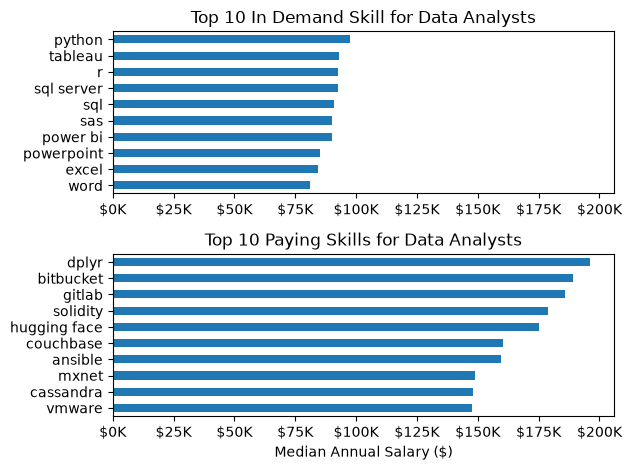

In [104]:
#Plot the data
fig, ax = plt.subplots(2,1)
fig.tight_layout()

#skills plot
top_skills[::-1].plot(kind='barh', y='median',  ax=ax[0],legend=False) #Call the df in reverse order as a way to invert yaxis plotting

#Pay plot
top_pay.plot(kind='barh', y='median',ax=ax[1],legend=False)

#customise skills
ax[0].set_title('Top 10 In Demand Skill for Data Analysts')
ax[0].set_ylabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _ : f'${int(x/1_000)}K'))
ax[0].set_xlim(ax[1].get_xlim()) #can use this to automate xlims, but must come after plotting

#customise pay
ax[1].set_title('Top 10 Paying Skills for Data Analysts')
ax[1].invert_yaxis()
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Annual Salary ($)')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _ : f'${int(x/1_000)}K'))

fig.tight_layout()
plt.show()


# Seaborn

Built on top of Matplotlib, specialised for visualisations

In [105]:
#Install and import seaborn
import seaborn as sns

## Bar Charts

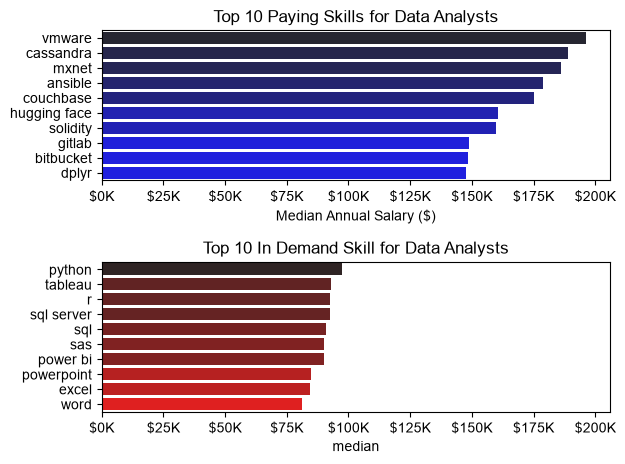

In [106]:
#using pay and skills data from earlier, modify the plot using Seaborn

#Plot the data
fig, ax = plt.subplots(2,1)
fig.tight_layout()

#MatPlotLib code
#top_pay.plot(kind='barh', y='median',ax=ax[0],legend=False)
#top_skills[::-1].plot(kind='barh', y='median',  ax=ax[1],legend=False) #Call the df in reverse order as a way to invert yaxis plotting

#Seaborn code
sns.barplot(top_pay[::-1], #provide data 
            x='median',  #set x
            y=top_pay.index, #set y
            ax=ax[0], #ax id
            hue='median', #data for colouring 
            palette='dark:b_r', #palette (dark:b), _r reverses order of colour plotting (light->dark/dark->light)
            legend=False) #remove legend
sns.barplot(top_skills,x='median', y=top_skills.index, ax=ax[1], hue='median', palette='dark:r_r', legend=False)

#customise pay
ax[0].set_title('Top 10 Paying Skills for Data Analysts')
ax[0].invert_yaxis()
ax[0].set_ylabel('')
ax[0].set_xlabel('Median Annual Salary ($)')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _ : f'${int(x/1_000)}K'))

#customise skills
ax[1].set_title('Top 10 In Demand Skill for Data Analysts')
ax[1].set_ylabel('')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _ : f'${int(x/1_000)}K'))
ax[1].set_xlim(ax[0].get_xlim()) #can use this to automate xlims, but must come after plotting

#Can set themes
sns.set_theme(style='ticks')

fig.tight_layout()
plt.show()


## Histograms

<Axes: xlabel='salary_year_avg', ylabel='Count'>

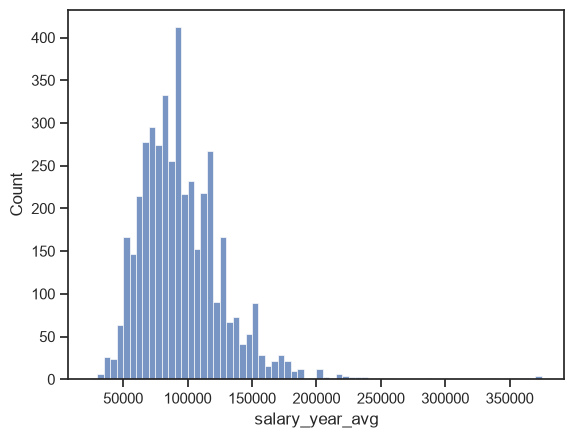

In [107]:
#Old histogram Plot
#us_da['salary_year_avg'].plot(kind='hist')

#New histogram with Seaborn
sns.histplot(us_da, x = 'salary_year_avg')



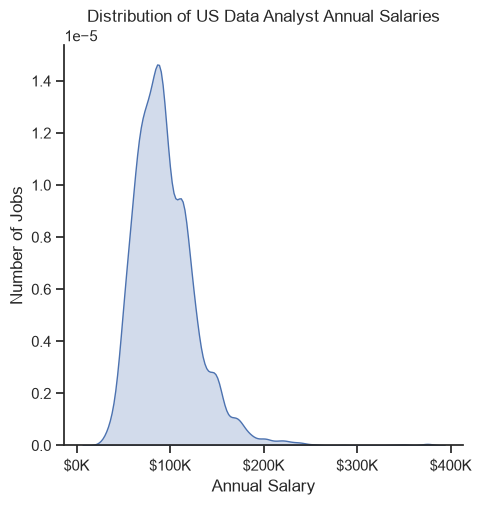

In [108]:
#Can also plot the data with a distribution plot for smoother lines

sns.displot(us_da, 
            x='salary_year_avg',
            kind = 'kde',
            fill=True)
plt.title('Distribution of US Data Analyst Annual Salaries')
plt.xlabel('Annual Salary')
plt.ylabel('Number of Jobs')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))


## Box Plots

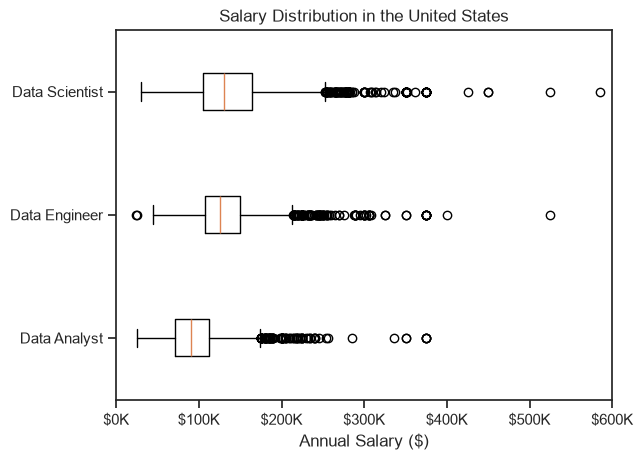

In [109]:
#Old Boxplot
plt.boxplot(job_list, tick_labels=job_titles, orientation='horizontal')

plt.title('Salary Distribution in the United States')
plt.xlabel('Annual Salary ($)')
plt.ylabel('')

ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000):,}K')) #format the xaxis

plt.xlim(0,600_000) #filter out some outliers and focus more on the majority of data

plt.show()

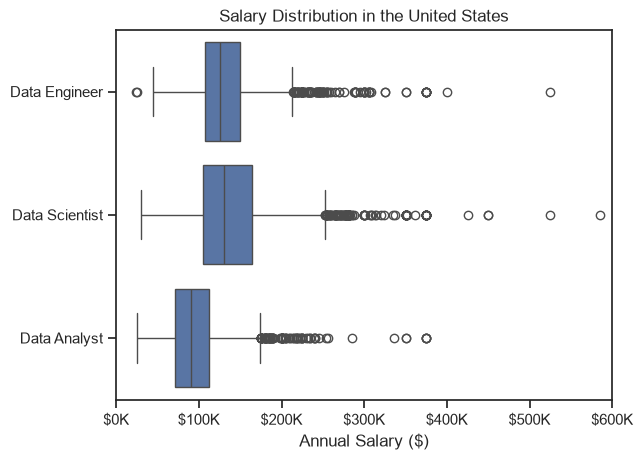

In [110]:
#Seaborn Boxplot

sns.boxplot(data=df_usa2[df_usa2['job_title_short'].isin(job_titles)],
            x = 'salary_year_avg',
            y = 'job_title_short')
plt.title('Salary Distribution in the United States')
plt.xlabel('Annual Salary ($)')
plt.ylabel('')
ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000):,}K')) #format the xaxis
plt.xlim(0,600_000) #filter out some outliers and focus more on the majority of data
plt.show()
